In [2]:
import pandas as pd
df = pd.read_csv("/Users/donalsaji/Desktop/Project Work/Sem 2/Python/president_heights1.csv")
df.head()

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
3,44,Barack Obama,NaN
4,23,Benjamin Harrison,168.0


In [3]:
print(df.iloc[0:6,1:3])

                name  height(cm)
0    Abraham Lincoln       193.0
1     Andrew Jackson       185.0
2     Andrew Johnson       178.0
3       Barack Obama         NaN
4  Benjamin Harrison       168.0
5       Bill Clinton       188.0


In [4]:
print(df.iloc[0:20:2])

    order                  name  height(cm)
0      16       Abraham Lincoln       193.0
2      17        Andrew Johnson       178.0
4      23     Benjamin Harrison       168.0
6      30       Calvin Coolidge       178.0
8      34  Dwight D. Eisenhower       179.0
10     14       Franklin Pierce         NaN
12     43        George W. Bush       182.0
14     38           Gerald Ford         NaN
16     31        Herbert Hoover       182.0
18     15        James Buchanan       183.0


In [5]:
Ffill=df.ffill()
print(Ffill.shape)

(42, 3)


<Axes: title={'center': 'Top 5 Tallest Presidents'}, xlabel='name'>

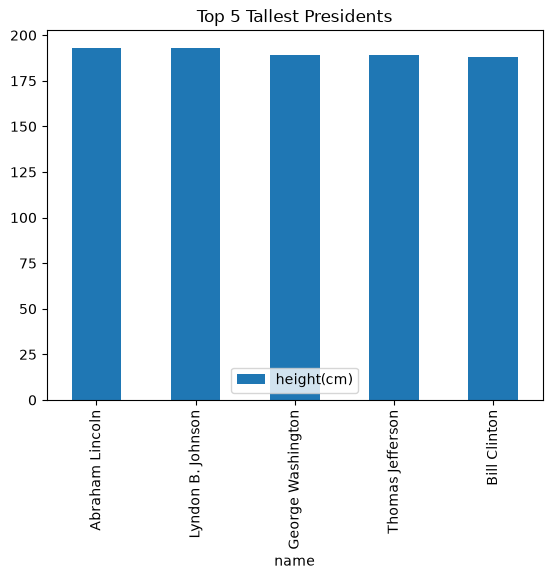

In [6]:
top5=df.nlargest(5, 'height(cm)')
top5.plot.bar(x='name', y='height(cm)', title='Top 5 Tallest Presidents')

<Axes: title={'center': 'Height Distribution'}, ylabel='Frequency'>

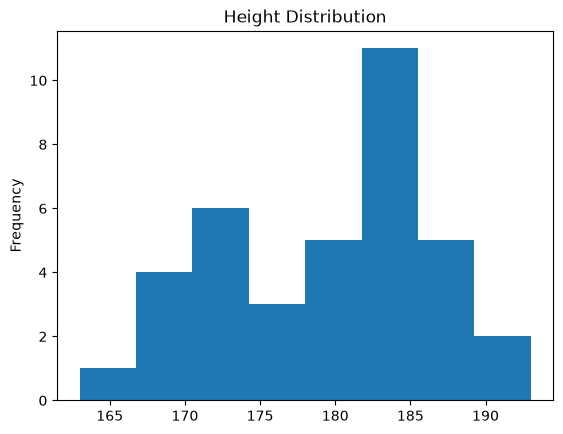

In [7]:
df['height(cm)'].plot.hist(bins=8, title="Height Distribution")

In [9]:
df1 = df.dropna()
df1['era'] = pd.cut(df1['order'], bins=[0, 15, 30 ,45], labels=['Early era', 'Middle era', 'Modern era'])
df1.head()
df_mult= df1.set_index(['era', 'name']).sort_index()
df_mult.head(20)

order  height(cm)
era        name                                     
Early era  Andrew Jackson              7       185.0
           George Washington           1       189.0
           James Buchanan             15       183.0
           James K. Polk              11       173.0
           James Madison               4       163.0
           James Monroe                5       183.0
           John Adams                  2       170.0
           John Quincy Adams           6       171.0
           John Tyler                 10       183.0
           Martin Van Buren            8       168.0
           Millard Fillmore           13       175.0
           Thomas Jefferson            3       189.0
           William Henry Harrison      9       173.0
           Zachary Taylor             12       173.0
Middle era Abraham Lincoln            16       193.0
           Andrew Johnson             17       178.0
           Benjamin Harrison          23       168.0
           Calvin Coolidge            30       178.0
           Chester A. Arthur          21       183.0
           Rutherford B. Hayes        19       174.0

In [10]:
#pick first four information from presidents_heihgts1 and create a dataframe
reshape = df.dropna().head(4)
reshape

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
4,23,Benjamin Harrison,168.0


In [11]:
melted = pd.melt(
    reshape,
    id_vars=['name', 'order'],
    value_vars=['height(cm)'],
    var_name='metric',
    value_name='value'
)
print("---Melted Data----")
print(melted)

---Melted Data----
                name  order      metric  value
0    Abraham Lincoln     16  height(cm)  193.0
1     Andrew Jackson      7  height(cm)  185.0
2     Andrew Johnson     17  height(cm)  178.0
3  Benjamin Harrison     23  height(cm)  168.0


In [12]:
pivoted = reshape.pivot(index ='order', columns='name', values='height(cm)')
print("---Pivoted Data----")
print(pivoted)

---Pivoted Data----
name   Abraham Lincoln  Andrew Jackson  Andrew Johnson  Benjamin Harrison
order                                                                    
7                  NaN           185.0             NaN                NaN
16               193.0             NaN             NaN                NaN
17                 NaN             NaN           178.0                NaN
23                 NaN             NaN             NaN              168.0


In [13]:
reshape['height_category'] = pd.cut(reshape['height(cm)'], bins=3, labels=['Short', 'Medium', 'Tall'])

#Summary statistics grouped by height category
pivot_tbl=reshape.pivot_table(index='height_category', values='height(cm)', aggfunc=['mean', 'count', 'sum'],observed=False)
print(reshape)
print("---Pivot Table---")
print(pivot_tbl)

   order               name  height(cm) height_category
0     16    Abraham Lincoln       193.0            Tall
1      7     Andrew Jackson       185.0            Tall
2     17     Andrew Johnson       178.0          Medium
4     23  Benjamin Harrison       168.0           Short
---Pivot Table---
                      mean      count        sum
                height(cm) height(cm) height(cm)
height_category                                 
Short                168.0          1      168.0
Medium               178.0          1      178.0
Tall                 189.0          2      378.0


In [14]:
reshape_indexed = reshape.set_index(['order', 'name'])
stacked = reshape_indexed.stack()

unstacked = stacked.unstack()

print("---Stacked series---")
print(stacked.head(4))

---Stacked series---
order  name                            
16     Abraham Lincoln  height(cm)         193.0
                        height_category     Tall
7      Andrew Jackson   height(cm)         185.0
                        height_category     Tall
dtype: object
